# 09 — Bônus II: CNNs do estado da arte, aumento de dados e mapas de ativação (CAM)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

O notebook 07 trouxe do survey de previsão (Kong et al., 2025) os Transformers com patches. Este notebook traz três ideias do survey de **classificação** de séries, Foumani et al., *Deep Learning for Time Series Classification and Extrinsic Regression: A Current Survey* (ACM Computing Surveys, 2024), escolhidas por atacarem os pontos fracos que o trabalho mostrou até aqui.

| Parte | Ideia do survey | Pergunta que responde |
|---|---|---|
| **A** | **FCN, ResNet e InceptionTime** (seção 3.2 do survey), as CNNs de referência em classificação de séries, mais o **conjunto (*ensemble*) de sementes**, ideia central da InceptionTime | As CNNs de ponta superam a nossa CNN-1D simples? Juntar as 3 sementes ajuda? |
| **B** | **Aumento de dados** (seção 5): deformação do tempo, escala e deformação de amplitude | O gargalo é a variação entre pessoas com poucos vídeos (todos os modelos chegam a ~100% no treino). Gerar variações do treino reduz o sobreajuste? |
| **C** | **CAM — *Class Activation Map*** (seção 3.2), possível em redes com média global (GAP) | Em quais instantes, e em quais partes do corpo, a CNN-1D se baseia? Isso conversa com o resultado do horizonte (notebook 05)? |

O que **não** entrou, e por quê: as redes de grafos espaço-temporais (seção 3.5) são naturais para esqueletos, mas exigem uma implementação longa em Keras; o pré-treino auto-supervisionado e a transferência (seções 4 e 6) exigem outra base grande; as transformações de série em imagem (GAF, *recurrence plot*), segundo o próprio survey, não trazem ganho significativo. As três ficam como trabalho futuro.

Mesmo protocolo de todo o trabalho: 4 rodadas por sinalizante, 3 sementes, *early stopping* na validação, z-score ajustado só no treino, teste pareado de Wilcoxon.

**Tempo com GPU:** ~1h30. O notebook grava cada treino e continua de onde parou.

## 1. Configuração

In [1]:
import os, sys, time, warnings
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from scipy.interpolate import CubicSpline
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

warnings.filterwarnings("ignore", message=".*shuffle=True.*")
SEMENTES = [0, 1, 2]
RODADAS = [0, 1, 2, 3]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules
DRIVE_OK = False
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive", force_remount=True)
        BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
        DRIVE_OK = True
    except Exception as e:
        print("AVISO: não consegui montar o Google Drive:", e)
        BASE = Path("/content/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
PROBS, PESOS = RES / "09_probabilidades", RES / "09_pesos"
for p in (DADOS, FIG, RES, PROBS, PESOS):
    p.mkdir(parents=True, exist_ok=True)
if not (DADOS / "minds_st.npz").exists():
    if IN_COLAB:
        from google.colab import files
        print("Envie o arquivo minds_st.npz (selecione SÓ ele):")
        enviados = files.upload()
        nome = next(n for n in enviados if n.startswith("minds_st"))
        (DADOS / "minds_st.npz").write_bytes(enviados[nome])
    else:
        raise FileNotFoundError(f"Não achei {DADOS / 'minds_st.npz'} (rode o notebook 00).")
ARQ_A, ARQ_B = RES / "09_cnns_por_rodada.csv", RES / "09_aumento_por_rodada.csv"

def salvar_fig(nome):
    plt.savefig(FIG / f"09_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"].astype(np.float32), d["y"]
classes, cols = d["classes"].astype(str), d["cols"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
K = len(classes)

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def media_dp(X, tr):
    return X[tr].reshape(-1, X.shape[-1]).mean(0), X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6

def padronizar(X, tr):
    mu, sd = media_dp(X, tr)
    return ((X - mu) / sd).astype(np.float32)

def diferenca(X):
    return np.diff(X, axis=1, prepend=X[:, :1]).astype(np.float32)        # Δx_1 = 0, como no notebook 06

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))

def ler(arq):
    return pd.read_csv(arq) if arq.exists() else pd.DataFrame(columns=["modelo", "rodada", "semente"])

def gravar(arq, df, linha):
    df = pd.concat([df, pd.DataFrame([linha])], ignore_index=True)
    df.to_csv(arq, index=False)
    return df

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
print(f"séries {N} | T={T} | F={F} | {K} classes")

I0000 00:00:1795547902.365028   84860 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795547905.505869   84860 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


séries 1158 | T=32 | F=321 | 20 classes


## 2. Parte A — CNNs do estado da arte

As três arquiteturas que o survey aponta como referência em classificação de séries, aqui com a mesma entrada (sinal bruto, 32 × 321) e a mesma regularização das nossas redes (ruído gaussiano 0,1 na entrada e *dropout* 0,3 antes da saída), para que a diferença venha só do corpo da rede:

- **FCN** (Wang et al., 2017): 3 convoluções (128, 256 e 128 filtros; núcleos 8, 5 e 3), cada uma com *batch norm* e ReLU, e média global (GAP). É a nossa CNN-1D com mais filtros e núcleos maiores.
- **ResNet** (Wang et al., 2017): 3 blocos residuais (64, 128 e 128 filtros), cada um com 3 convoluções (núcleos 8, 5 e 3) e um atalho que soma a entrada do bloco à saída. É a rede que liderou a comparação de Fawaz et al. (2019).
- **InceptionTime** (Fawaz et al., 2020): 6 módulos *Inception*; cada módulo comprime os canais (*bottleneck* de 32), aplica em paralelo convoluções com núcleos de tamanhos diferentes e um *max-pooling*, e concatena (128 mapas). Há um atalho residual a cada 3 módulos. Os núcleos originais (10, 20 e 40) foram pensados para séries com centenas de instantes; com só 32 instantes usamos **3, 5 e 9**, o que ainda dá um campo receptivo maior do que o sinal inteiro.

**Conjunto de sementes.** A InceptionTime original é um conjunto de 5 redes iguais com inicializações diferentes, cuja saída é a média das probabilidades. Fazemos o mesmo com as 3 sementes de **cada** modelo, inclusive a CNN-1D, para a comparação ser justa. As probabilidades de teste de cada treino são gravadas, então o conjunto não custa treino extra.

In [2]:
def entrada(F_in):
    x_in = keras.Input(shape=(T, F_in))
    return x_in, layers.GaussianNoise(0.1)(x_in)

def saida(x_in, h, nome):
    h = layers.GlobalAveragePooling1D(name="gap")(h)
    return keras.Model(x_in, layers.Dense(K, activation="softmax", name="saida")(layers.Dropout(0.3)(h)), name=nome)

def conv_bn_relu(h, filtros, k):
    return layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(filtros, k, padding="same")(h)))

def cnn1d(F_in=F):
    x_in, h = entrada(F_in)
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = conv_bn_relu(h, filtros, k)
    return saida(x_in, h, "CNN-1D")

def fcn(F_in=F):
    x_in, h = entrada(F_in)
    for filtros, k in [(128, 8), (256, 5), (128, 3)]:
        h = conv_bn_relu(h, filtros, k)
    return saida(x_in, h, "FCN")

def resnet(F_in=F):
    x_in, h = entrada(F_in)
    for filtros in (64, 128, 128):
        r = conv_bn_relu(h, filtros, 8)
        r = conv_bn_relu(r, filtros, 5)
        r = layers.BatchNormalization()(layers.Conv1D(filtros, 3, padding="same")(r))
        atalho = layers.BatchNormalization()(layers.Conv1D(filtros, 1, padding="same")(h) if h.shape[-1] != filtros else h)
        h = layers.Activation("relu")(layers.Add()([r, atalho]))
    return saida(x_in, h, "ResNet")

def modulo_inception(h, nucleos=(3, 5, 9), filtros=32):
    b = layers.Conv1D(filtros, 1, padding="same", use_bias=False)(h)                      # bottleneck
    ramos = [layers.Conv1D(filtros, k, padding="same", use_bias=False)(b) for k in nucleos]
    ramos.append(layers.Conv1D(filtros, 1, padding="same", use_bias=False)(layers.MaxPooling1D(3, 1, padding="same")(h)))
    return layers.Activation("relu")(layers.BatchNormalization()(layers.Concatenate()(ramos)))

def inceptiontime(F_in=F, profundidade=6):
    x_in, h = entrada(F_in)
    res = h
    for i in range(profundidade):
        h = modulo_inception(h)
        if i % 3 == 2:                                                                       # atalho a cada 3 módulos
            atalho = layers.BatchNormalization()(layers.Conv1D(h.shape[-1], 1, padding="same", use_bias=False)(res))
            h = layers.Activation("relu")(layers.Add()([h, atalho]))
            res = h
    return saida(x_in, h, "InceptionTime")

MODELOS_A = {"CNN-1D": cnn1d, "FCN": fcn, "ResNet": resnet, "InceptionTime": inceptiontime}
PARAM = {}
for nome, f in MODELOS_A.items():
    PARAM[nome] = f().count_params()
    keras.backend.clear_session()
display(pd.Series(PARAM, name="parâmetros").map("{:,}".format).to_frame())

,parâmetros
CNN-1D,"197,012"
FCN,"595,988"
ResNet,"693,460"
InceptionTime,"230,100"


### Treino

Adam com taxa 10⁻³ (a mesma dos artigos originais da FCN, ResNet e InceptionTime), entropia cruzada, *early stopping* pela perda de validação (paciência 25) e redução da taxa pela metade quando a validação estaciona. Para a CNN-1D da semente 0, os pesos de cada rodada são gravados para a Parte C.

In [3]:
resA = ler(ARQ_A)
feitos = set(zip(resA.modelo, resA.rodada, resA.semente))
for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for nome, construtor in MODELOS_A.items():
        for s in SEMENTES:
            if (nome, k, s) in feitos:
                continue
            keras.utils.set_random_seed(s)
            m = construtor()
            m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"], jit_compile=False)
            t_ini = time.time()
            h = m.fit(Z[tr], y[tr], validation_data=(Z[va], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE,
                      callbacks=callbacks(), verbose=0)
            t_treino = time.time() - t_ini
            t0 = time.time(); prob = m.predict(Z[te], verbose=0); t_inf = (time.time() - t0) / len(te) * 1000
            np.save(PROBS / f"{nome}_r{k}_s{s}.npy", prob.astype(np.float32))
            if nome == "CNN-1D" and s == 0:
                m.save_weights(PESOS / f"cnn1d_bruto_r{k}.weights.h5")
            epocas = len(h.history["loss"])
            resA = gravar(ARQ_A, resA, dict(modelo=nome, rodada=k, semente=s, parametros=m.count_params(), epocas=epocas,
                                            melhor_epoca=int(np.argmin(h.history["val_loss"])) + 1, tempo_s=t_treino,
                                            s_por_epoca=t_treino / epocas, ms_por_video=t_inf,
                                            acc_treino_final=h.history["accuracy"][-1], **metricas(y[te], prob.argmax(1))))
            print(f"rodada {k} | {nome:13s} | semente {s} | F1 teste {resA.f1_macro.iloc[-1]:.3f} | {epocas} épocas "
                  f"| {t_treino:.0f}s", flush=True)
            keras.backend.clear_session()
print("treinos da parte A:", len(pd.read_csv(ARQ_A)))

rodada 0 | CNN-1D        | semente 0 | F1 teste 0.910 | 84 épocas | 47s


rodada 0 | CNN-1D        | semente 1 | F1 teste 0.866 | 45 épocas | 23s


rodada 0 | CNN-1D        | semente 2 | F1 teste 0.848 | 42 épocas | 26s


rodada 0 | FCN           | semente 0 | F1 teste 0.895 | 46 épocas | 31s


rodada 0 | FCN           | semente 1 | F1 teste 0.889 | 73 épocas | 50s


rodada 0 | FCN           | semente 2 | F1 teste 0.875 | 58 épocas | 37s


... (39 outputs left out)

rodada 3 | InceptionTime | semente 0 | F1 teste 0.890 | 36 épocas | 67s


rodada 3 | InceptionTime | semente 1 | F1 teste 0.834 | 34 épocas | 61s


rodada 3 | InceptionTime | semente 2 | F1 teste 0.909 | 43 épocas | 73s


treinos da parte A: 48


### Resultado da Parte A

Para cada modelo: F1 macro de uma rede só (média ± desvio das 4 rodadas × 3 sementes), diferença pareada em relação à CNN-1D (Wilcoxon, 12 pares), custo, e o F1 do **conjunto das 3 sementes** (média das probabilidades; 4 valores, um por rodada).

,F1 macro (%),acurácia bal. (%),parâmetros,treino (s),s/época,inferência (ms/vídeo),conjunto 3 sementes (%),ganho do conjunto (p.p.),Δ vs CNN-1D (p.p.),p (Wilcoxon),pares melhores
modelo,,,,,,,,,,,
CNN-1D,90.5 ± 2.7,91.1,"197,012",45,0.68,1.28,91.6 ± 3.0,+1.1,—,—,—
FCN,90.8 ± 2.5,91.3,"595,988",53,0.74,1.34,91.6 ± 2.2,+0.8,+0.3,0.910,7/12
ResNet,84.7 ± 5.9,85.5,"693,460",80,1.65,2.97,89.2 ± 3.6,+4.5,-5.8,0.009,1/12
InceptionTime,87.3 ± 3.2,88.0,"230,100",92,1.67,3.44,90.3 ± 3.3,+3.0,-3.2,0.009,2/12


F1 do conjunto por rodada (%):


,CNN-1D,FCN,ResNet,InceptionTime
0,87.3,89.2,89.4,89.0
1,94.2,93.8,93.9,94.3
2,91.9,90.3,85.4,86.5
3,93.0,93.0,87.9,91.3


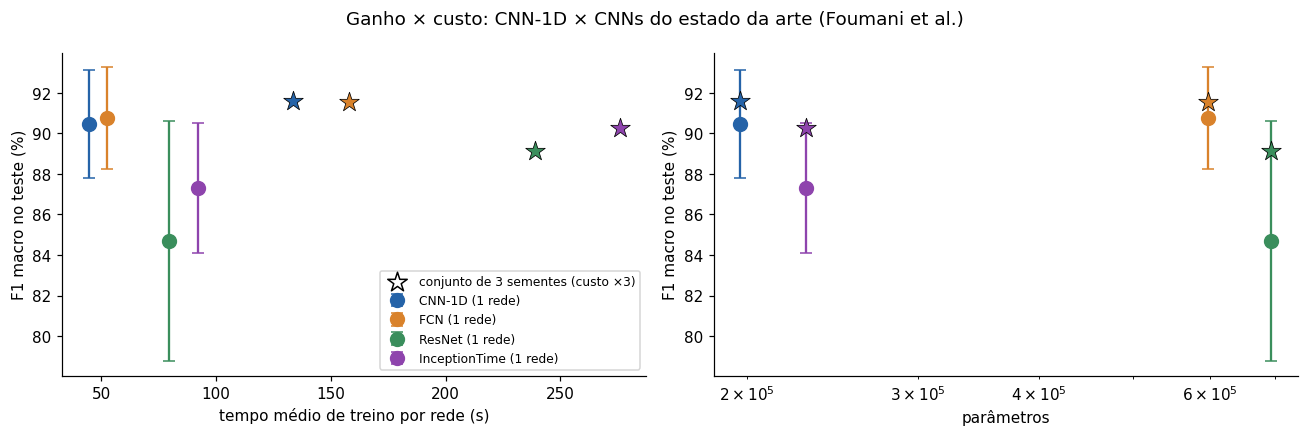

In [4]:
resA = pd.read_csv(ARQ_A)
base = resA[resA.modelo == "CNN-1D"].set_index(["rodada", "semente"]).f1_macro

def f1_conjunto(nome, k):
    _, _, te = particao(k)
    prob = np.mean([np.load(PROBS / f"{nome}_r{k}_s{s}.npy") for s in SEMENTES], axis=0)
    return f1_score(y[te], prob.argmax(1), average="macro")

conj = pd.DataFrame({nome: [f1_conjunto(nome, k) for k in RODADAS] for nome in MODELOS_A}, index=RODADAS)
linhas = []
for nome in MODELOS_A:
    r = resA[resA.modelo == nome]
    v = r.set_index(["rodada", "semente"]).f1_macro
    linha = {"modelo": nome, "F1 macro (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}",
             "acurácia bal. (%)": f"{100 * r.acuracia_balanceada.mean():.1f}",
             "parâmetros": f"{int(r.parametros.iloc[0]):,}", "treino (s)": f"{r.tempo_s.mean():.0f}",
             "s/época": f"{r.s_por_epoca.mean():.2f}", "inferência (ms/vídeo)": f"{r.ms_por_video.mean():.2f}",
             "conjunto 3 sementes (%)": f"{100 * conj[nome].mean():.1f} ± {100 * conj[nome].std():.1f}",
             "ganho do conjunto (p.p.)": f"{100 * (conj[nome].mean() - v.mean()):+.1f}"}
    if nome != "CNN-1D":
        delta = (v - base.reindex(v.index)).dropna()
        p = wilcoxon(delta).pvalue if len(delta) >= 6 and np.any(delta != 0) else np.nan
        linha.update({"Δ vs CNN-1D (p.p.)": f"{100 * delta.mean():+.1f}", "p (Wilcoxon)": f"{p:.3f}",
                      "pares melhores": f"{int((delta > 0).sum())}/{len(delta)}"})
    linhas.append(linha)
tabA = pd.DataFrame(linhas).set_index("modelo").fillna("—")
display(tabA)
tabA.to_csv(RES / "09_tabela_cnns.csv")
print("F1 do conjunto por rodada (%):")
display((100 * conj).round(1))

g = resA.groupby("modelo").agg(f1=("f1_macro", "mean"), dp=("f1_macro", "std"), treino=("tempo_s", "mean"),
                               param=("parametros", "first")).reindex(list(MODELOS_A))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
cores = ["#2563A8", "#D9822B", "#3A8E5C", "#8E44AD"]
for ax, col, rot in [(axs[0], "treino", "tempo médio de treino por rede (s)"), (axs[1], "param", "parâmetros")]:
    for (nome, row), cor in zip(g.iterrows(), cores):
        ax.errorbar(row[col], 100 * row.f1, yerr=100 * row.dp, fmt="o", ms=9, color=cor, capsize=4, label=f"{nome} (1 rede)")
        ax.scatter(row[col] * (3 if col == "treino" else 1), 100 * conj[nome].mean(), marker="*", s=180, color=cor,
                   edgecolor="k", lw=.5, zorder=3)
    ax.set_xlabel(rot); ax.set_ylabel("F1 macro no teste (%)")
axs[1].set_xscale("log")
axs[0].scatter([], [], marker="*", s=180, color="w", edgecolor="k", label="conjunto de 3 sementes (custo ×3)")
axs[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Ganho × custo: CNN-1D × CNNs do estado da arte (Foumani et al.)")
plt.tight_layout(); salvar_fig("cnns_ganho_custo"); plt.show()

## 3. Parte B — Aumento de dados

O survey (seção 5) recomenda o aumento de dados justamente para bases pequenas, em que as redes decoram o treino. As transformações foram escolhidas pelo que **simulam** em Libras:

| Transformação | O que faz | O que simula |
|---|---|---|
| **Deformação do tempo** (*time warping*, Um et al., 2017) | Uma curva suave de velocidade (*spline* com 4 nós, σ = 0,2) acelera e desacelera trechos do vídeo; **o mesmo** relógio vale para todos os canais, para o corpo continuar sincronizado | Pessoa que sinaliza mais rápido ou mais devagar em partes do sinal |
| **Escala** (*scaling*) | Multiplica cada canal por um fator ~ N(1; 0,1) | Proporções de corpo e mão diferentes (as coordenadas já estão centradas nos ombros) |
| **Deformação de amplitude** (*magnitude warping*) | Multiplica cada canal por uma curva suave ~ 1 ± 0,2 ao longo do tempo | Amplitude do movimento que varia ao longo do gesto |
| **Combinação** | Cada transformação é aplicada a cada vídeo com probabilidade 0,5 | Todas as anteriores juntas |

O *jittering* (ruído aditivo) já está em todas as redes do trabalho (camada de ruído gaussiano), por isso não aparece como condição separada.

**Onde aplicar.** Usamos a melhor configuração do trabalho, a **CNN-1D com a 1ª diferença (Δ)** (notebook 06). O aumento é feito no **sinal bruto**, a cada lote e a cada época (cada época vê versões novas); só depois se calcula Δ e se aplica o z-score, com média e desvio do treino **sem** aumento. Validação e teste nunca são aumentados. Valores ausentes (mão fora do quadro, gravada como 0) continuam ausentes depois do aumento.

A condição **sem aumento** passa pelo mesmo gerador de lotes, para que a única diferença entre as condições seja a transformação.

funções de aumento conferidas


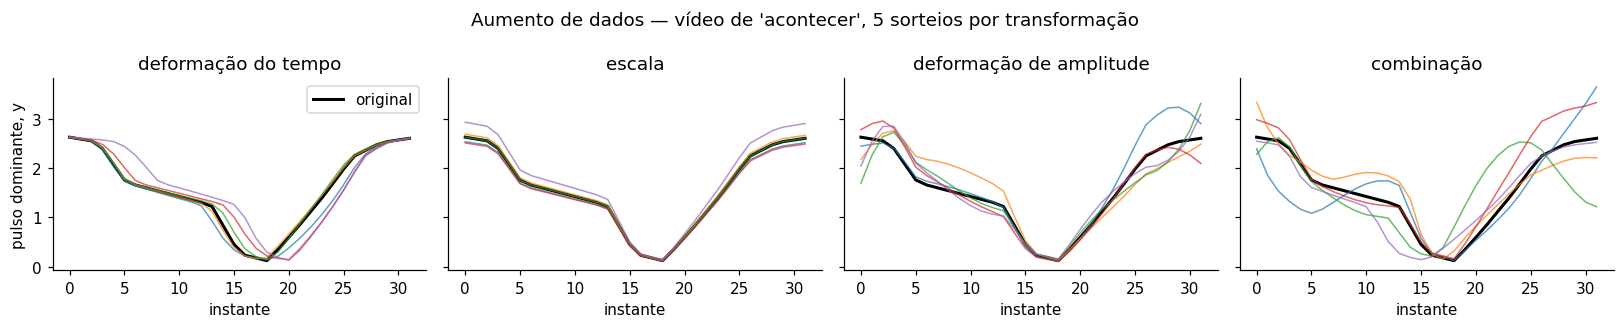

In [5]:
def _curva_suave(rng, n_curvas, sigma, nos=4):
    # curvas suaves ~ 1 ± sigma ao longo dos T instantes (spline cúbica em nos+2 pontos); devolve (T, n_curvas)
    xs = np.linspace(0, T - 1, nos + 2)
    return CubicSpline(xs, rng.normal(1.0, sigma, (nos + 2, n_curvas)), axis=0)(np.arange(T))

def escala(xb, rng, sigma=0.1):
    return xb * rng.normal(1.0, sigma, (len(xb), 1, xb.shape[-1])).astype(np.float32)

def deform_amplitude(xb, rng, sigma=0.2):
    B, _, Fx = xb.shape
    curvas = _curva_suave(rng, B * Fx, sigma).reshape(T, B, Fx).transpose(1, 0, 2)
    return (xb * curvas).astype(np.float32)

def deform_tempo(xb, rng, sigma=0.2):
    B = len(xb)
    vel = np.clip(_curva_suave(rng, B, sigma), 0.1, None)                  # velocidade local (T, B), sempre > 0
    pos = np.cumsum(vel, axis=0)
    pos = (pos - pos[0]) / (pos[-1] - pos[0]) * (T - 1)                    # novo relógio, de 0 a T-1
    pos = pos.T                                                             # (B, T)
    i0 = np.floor(pos).astype(int).clip(0, T - 2)
    fr = (pos - i0)[..., None].astype(np.float32)
    b = np.arange(B)[:, None]
    x0, x1 = xb[b, i0], xb[b, i0 + 1]
    novo = x0 * (1 - fr) + x1 * fr
    proximo = np.where(fr < 0.5, x0, x1)
    ausente = (x0 == 0) | (x1 == 0)                                         # não mistura valor real com ausência
    return np.where(ausente, proximo, novo).astype(np.float32)

def combinacao(xb, rng):
    for f in (deform_tempo, escala, deform_amplitude):
        sel = rng.random(len(xb)) < 0.5
        if sel.any():
            xb = xb.copy()
            xb[sel] = f(xb[sel], rng)
    return xb

def mantem_ausentes(f):
    def g(xb, rng):
        return np.where(xb == 0, 0, f(xb, rng)).astype(np.float32)
    return g

AUMENTOS = {"sem aumento": None, "deformação do tempo": deform_tempo, "escala": mantem_ausentes(escala),
            "deformação de amplitude": mantem_ausentes(deform_amplitude), "combinação": combinacao}

# conferências: sem sigma o aumento é a identidade; ausentes continuam ausentes; forma preservada
_rng = np.random.default_rng(0)
_xb = X[:8]
assert np.allclose(deform_tempo(_xb, _rng, sigma=0.0), _xb, atol=1e-5)
assert np.allclose(deform_amplitude(_xb, _rng, sigma=0.0), _xb, atol=1e-5)
for nome, f in AUMENTOS.items():
    if f is not None:
        _a = f(_xb, _rng)
        assert _a.shape == _xb.shape and np.isfinite(_a).all()
        if nome in ("escala", "deformação de amplitude"):
            assert np.all(_a[_xb == 0] == 0)
print("funções de aumento conferidas")

# figura: um vídeo e as versões aumentadas (posição vertical do pulso dominante)
j = int(np.where(cols == "dom0_y")[0][0])
v0 = int(np.argmax((X[:, :, j] != 0).all(1)))                              # primeiro vídeo sem mão ausente
fig, axs = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, (nome, f) in zip(axs, list(AUMENTOS.items())[1:]):
    ax.plot(X[v0, :, j], "k", lw=2, label="original")
    rng = np.random.default_rng(1)
    for _ in range(5):
        ax.plot(f(X[v0:v0 + 1], rng)[0, :, j], lw=1, alpha=.7)
    ax.set_title(nome); ax.set_xlabel("instante")
axs[0].set_ylabel("pulso dominante, y"); axs[0].legend()
fig.suptitle(f"Aumento de dados — vídeo de '{classes[y[v0]]}', 5 sorteios por transformação")
plt.tight_layout(); salvar_fig("exemplos_aumento"); plt.show()

In [6]:
def lotes_aumentados(Xtr, ytr, aumento, mu, sd, semente):
    rng = np.random.default_rng(semente)
    def gerador():
        ordem = rng.permutation(len(ytr))
        for i in range(0, len(ytr), LOTE):
            idx = ordem[i:i + LOTE]
            xb = Xtr[idx]
            if aumento is not None:
                xb = aumento(xb, rng)
            yield ((diferenca(xb) - mu) / sd).astype(np.float32), ytr[idx]
    return tf.data.Dataset.from_generator(gerador, output_signature=(
        tf.TensorSpec(shape=(None, T, F), dtype=tf.float32), tf.TensorSpec(shape=(None,), dtype=tf.int64))
    ).repeat().prefetch(2)                                                   # steps_per_epoch define o fim de cada época

resB = ler(ARQ_B)
feitos = set(zip(resB.modelo, resB.rodada, resB.semente))
for k in RODADAS:
    tr, va, te = particao(k)
    D = diferenca(X)
    mu, sd = media_dp(D, tr)
    Zd = ((D - mu) / sd).astype(np.float32)
    for nome, aumento in AUMENTOS.items():
        for s in SEMENTES:
            if (nome, k, s) in feitos:
                continue
            keras.utils.set_random_seed(s)
            m = cnn1d()
            m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"], jit_compile=False)
            t_ini = time.time()
            h = m.fit(lotes_aumentados(X[tr], y[tr].astype(np.int64), aumento, mu, sd, s), validation_data=(Zd[va], y[va]),
                      steps_per_epoch=int(np.ceil(len(tr) / LOTE)), epochs=MAX_EPOCAS, callbacks=callbacks(), verbose=0)
            t_treino = time.time() - t_ini
            pred = m.predict(Zd[te], verbose=0).argmax(1)
            ib = int(np.argmin(h.history["val_loss"]))
            resB = gravar(ARQ_B, resB, dict(modelo=nome, rodada=k, semente=s, epocas=len(h.history["loss"]),
                                            melhor_epoca=ib + 1, tempo_s=t_treino, acc_treino=h.history["accuracy"][ib],
                                            acc_validacao=h.history["val_accuracy"][ib], **metricas(y[te], pred)))
            print(f"rodada {k} | {nome:24s} | semente {s} | F1 teste {resB.f1_macro.iloc[-1]:.3f} "
                  f"| {len(h.history['loss'])} épocas | {t_treino:.0f}s", flush=True)
            keras.backend.clear_session()
print("treinos da parte B:", len(pd.read_csv(ARQ_B)))

rodada 0 | sem aumento              | semente 0 | F1 teste 0.888 | 200 épocas | 144s


rodada 0 | sem aumento              | semente 1 | F1 teste 0.894 | 129 épocas | 86s


rodada 0 | sem aumento              | semente 2 | F1 teste 0.933 | 200 épocas | 144s


rodada 0 | deformação do tempo      | semente 0 | F1 teste 0.899 | 143 épocas | 144s


rodada 0 | deformação do tempo      | semente 1 | F1 teste 0.876 | 88 épocas | 59s


rodada 0 | deformação do tempo      | semente 2 | F1 teste 0.903 | 94 épocas | 84s


... (51 outputs left out)

rodada 3 | combinação               | semente 0 | F1 teste 0.918 | 68 épocas | 43s


rodada 3 | combinação               | semente 1 | F1 teste 0.945 | 70 épocas | 86s


rodada 3 | combinação               | semente 2 | F1 teste 0.913 | 53 épocas | 36s


treinos da parte B: 60


### Resultado da Parte B

F1 macro da CNN-1D + Δ com cada aumento, diferença pareada em relação a **sem aumento** (Wilcoxon, 12 pares) e a distância entre a acurácia de treino e a de validação na melhor época (quanto menor, menos sobreajuste).

,F1 macro (%),acurácia bal. (%),treino − validação (p.p.),melhor época,treino (s),Δ vs sem aumento (p.p.),p (Wilcoxon),pares melhores
aumento,,,,,,,,
sem aumento,93.3 ± 2.4,93.8,5.9,92,79,—,—,—
deformação do tempo,92.9 ± 2.4,93.4,5.8,68,76,-0.4,0.266,5/12
escala,93.0 ± 2.4,93.5,6.1,73,72,-0.2,0.622,5/12
deformação de amplitude,91.8 ± 2.0,92.3,7.8,62,58,-1.4,0.064,3/12
combinação,92.8 ± 2.3,93.2,7.6,60,60,-0.5,0.380,4/12


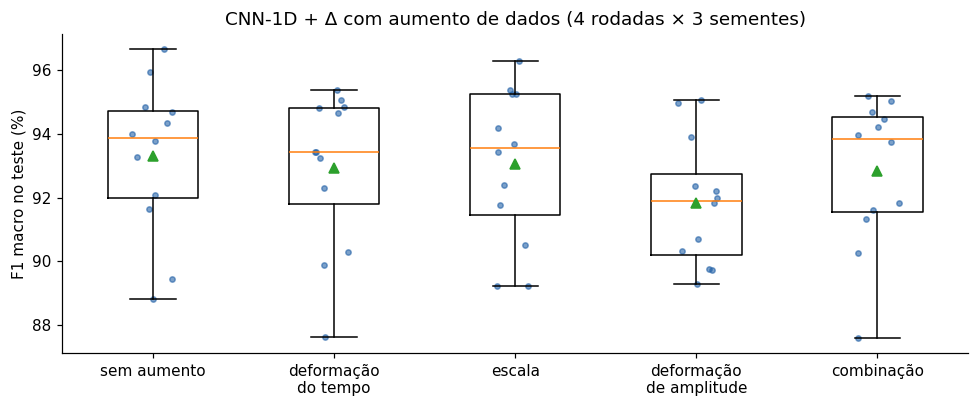

In [7]:
resB = pd.read_csv(ARQ_B)
baseB = resB[resB.modelo == "sem aumento"].set_index(["rodada", "semente"]).f1_macro
linhas = []
for nome in AUMENTOS:
    r = resB[resB.modelo == nome]
    v = r.set_index(["rodada", "semente"]).f1_macro
    linha = {"aumento": nome, "F1 macro (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}",
             "acurácia bal. (%)": f"{100 * r.acuracia_balanceada.mean():.1f}",
             "treino − validação (p.p.)": f"{100 * (r.acc_treino - r.acc_validacao).mean():.1f}",
             "melhor época": f"{r.melhor_epoca.mean():.0f}", "treino (s)": f"{r.tempo_s.mean():.0f}"}
    if nome != "sem aumento":
        delta = (v - baseB.reindex(v.index)).dropna()
        p = wilcoxon(delta).pvalue if len(delta) >= 6 and np.any(delta != 0) else np.nan
        linha.update({"Δ vs sem aumento (p.p.)": f"{100 * delta.mean():+.1f}", "p (Wilcoxon)": f"{p:.3f}",
                      "pares melhores": f"{int((delta > 0).sum())}/{len(delta)}"})
    linhas.append(linha)
tabB = pd.DataFrame(linhas).set_index("aumento").fillna("—")
display(tabB)
tabB.to_csv(RES / "09_tabela_aumento.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
nomes = list(AUMENTOS)
dados_box = [100 * resB[resB.modelo == n].f1_macro.values for n in nomes]
ax.boxplot(dados_box, widths=.5, showmeans=True)
for i, v in enumerate(dados_box, 1):
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v, s=12, alpha=.6, color="#2563A8")
ax.set_xticks(range(1, len(nomes) + 1), [n.replace(" de ", "\nde ").replace(" do ", "\ndo ") for n in nomes])
ax.set_ylabel("F1 macro no teste (%)"); ax.set_title("CNN-1D + Δ com aumento de dados (4 rodadas × 3 sementes)")
plt.tight_layout(); salvar_fig("aumento"); plt.show()

## 4. Parte C — Onde a CNN-1D olha: CAM e gradiente × entrada

A CNN-1D termina em média global (GAP) seguida de uma camada densa. Por isso, para a classe $c$, o **CAM** (Zhou et al., 2016; usado em séries por Wang et al., 2017) é

$$\text{CAM}_c(t) = \sum_k w_{k,c}\, A_k(t),$$

em que $A_k(t)$ é o mapa $k$ da última convolução no instante $t$ e $w_{k,c}$ é o peso da camada densa. Ele diz **quando** está a evidência da classe. Como as convoluções misturam os 321 canais desde a primeira camada, o CAM não separa as partes do corpo; para isso usamos o **gradiente × entrada** ($x \cdot \partial z_c/\partial x$, em que $z_c$ é a pontuação da classe antes do *softmax*), somado em valor absoluto dentro de cada grupo de canais.

Usamos as CNN-1D (sinal bruto, semente 0) treinadas na Parte A, uma por rodada, cada uma aplicada aos vídeos de **seus** sinalizantes de teste, sempre para a classe verdadeira. Cada mapa é normalizado pelo próprio máximo antes da média, para que todos os vídeos pesem igual.

In [8]:
GRUPOS = {"pose (corpo)": "pose", "mão dominante": "dom", "outra mão": "outra",
          "dedos dom. (rel. ao pulso)": "fdom", "dedos outra (rel. ao pulso)": "foutra"}
grupo_col = np.array([next(g for g, pre in GRUPOS.items() if c.split("_")[0].rstrip("0123456789") == pre) for c in cols])
assert pd.Series(grupo_col).value_counts().sum() == F

cam_tudo, gxi_tudo, y_tudo, acerto_tudo = [], [], [], []
for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    m = cnn1d()
    m.load_weights(PESOS / f"cnn1d_bruto_r{k}.weights.h5")
    ult_conv = [l for l in m.layers if isinstance(l, layers.Activation)][-1].output
    sub = keras.Model(m.input, [ult_conv, m.get_layer("gap").output])
    W, bias = m.get_layer("saida").get_weights()
    xt = tf.constant(Z[te])
    with tf.GradientTape() as fita:
        fita.watch(xt)
        A, g = sub(xt, training=False)
        z = tf.matmul(g, W) + bias                                           # pontuações antes do softmax
        z_c = tf.gather(z, y[te], axis=1, batch_dims=1)
    grad = fita.gradient(z_c, xt).numpy()
    A = A.numpy()
    cam = np.einsum("ntk,kn->nt", A, W[:, y[te]])                            # CAM da classe verdadeira
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max(1, keepdims=True) + 1e-9)
    gxi = np.abs(Z[te] * grad).sum(1)                                        # (n, F): soma nos instantes
    cam_tudo.append(cam); gxi_tudo.append(gxi); y_tudo.append(y[te])
    acerto_tudo.append(z.numpy().argmax(1) == y[te])
    keras.backend.clear_session()
cam_tudo, gxi_tudo = np.concatenate(cam_tudo), np.concatenate(gxi_tudo)
y_tudo, acerto_tudo = np.concatenate(y_tudo), np.concatenate(acerto_tudo)
print(f"mapas calculados para {len(y_tudo)} vídeos de teste | acurácia dessas redes: {acerto_tudo.mean():.3f}")

# quanto da evidência (CAM) está na 1ª metade do sinal
frac_1a = cam_tudo[:, :T // 2].sum(1) / (cam_tudo.sum(1) + 1e-9)
print(f"fração do CAM nos primeiros 50% do sinal: média {frac_1a.mean():.2f} "
      f"(acertos {frac_1a[acerto_tudo].mean():.2f}, erros {frac_1a[~acerto_tudo].mean():.2f})")

mapas calculados para 1158 vídeos de teste | acurácia dessas redes: 0.923
fração do CAM nos primeiros 50% do sinal: média 0.54 (acertos 0.53, erros 0.56)


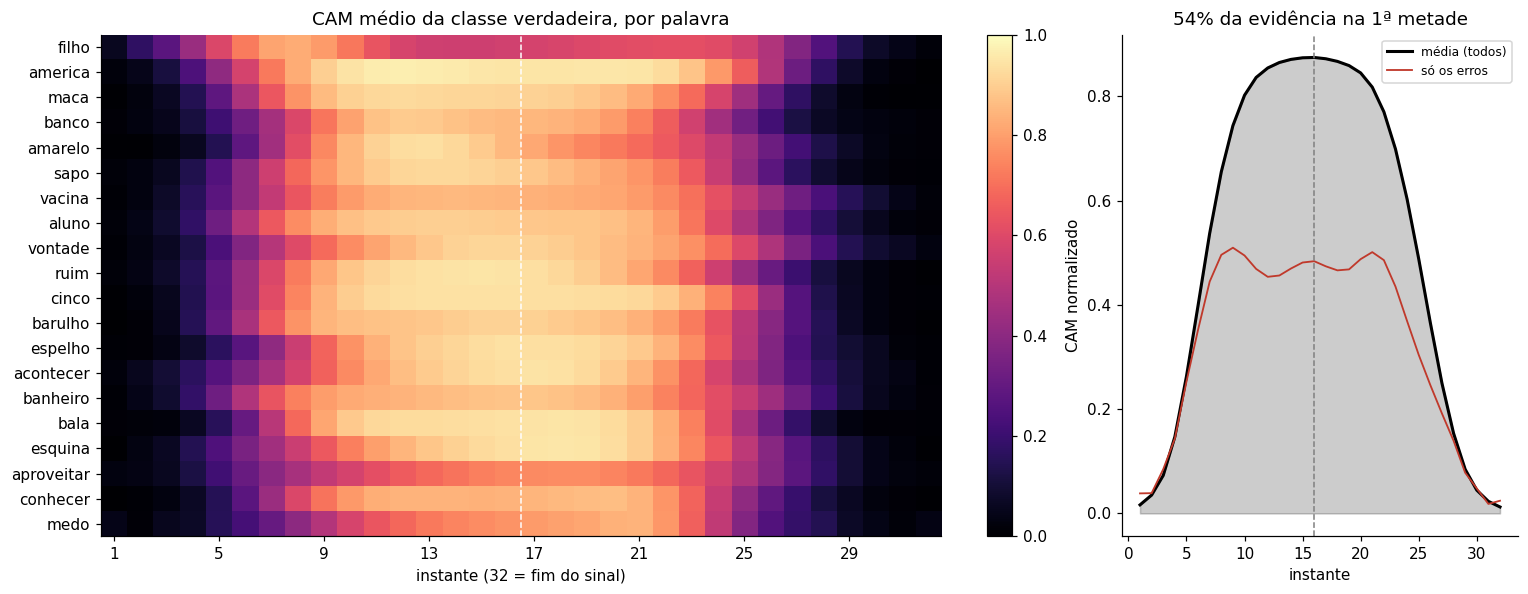

In [9]:
cam_classe = pd.DataFrame([cam_tudo[y_tudo == c].mean(0) for c in range(K)], index=classes)
ordem = cam_classe.idxmax(axis=1).sort_values().index                       # palavras ordenadas pelo pico
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [3, 1.3]})
im = axs[0].imshow(cam_classe.loc[ordem], aspect="auto", cmap="magma", vmin=0, vmax=1)
axs[0].set_yticks(range(K), ordem); axs[0].set_xlabel("instante (32 = fim do sinal)")
axs[0].set_xticks(range(0, T, 4), [str(t + 1) for t in range(0, T, 4)])
axs[0].axvline(T / 2 - .5, color="w", ls="--", lw=1)
axs[0].set_title("CAM médio da classe verdadeira, por palavra")
plt.colorbar(im, ax=axs[0], fraction=.03)
media = cam_tudo.mean(0)
axs[1].plot(np.arange(1, T + 1), media, "k", lw=2, label="média (todos)")
axs[1].plot(np.arange(1, T + 1), cam_tudo[~acerto_tudo].mean(0), color="#C0392B", lw=1.2, label="só os erros")
axs[1].fill_between(np.arange(1, T + 1), media, alpha=.2, color="k")
axs[1].axvline(T / 2, color="gray", ls="--", lw=1)
axs[1].set_xlabel("instante"); axs[1].set_ylabel("CAM normalizado"); axs[1].legend(fontsize=8)
axs[1].set_title(f"{100 * frac_1a.mean():.0f}% da evidência na 1ª metade")
plt.tight_layout(); salvar_fig("cam"); plt.show()

,canais,fração dos canais (%),fração da relevância (%),relevância por canal (× média)
pose (corpo),75,23.4,24.1,1.03
mão dominante,63,19.6,17.2,0.88
outra mão,63,19.6,15.1,0.77
dedos dom. (rel. ao pulso),60,18.7,29.4,1.57
dedos outra (rel. ao pulso),60,18.7,14.2,0.76


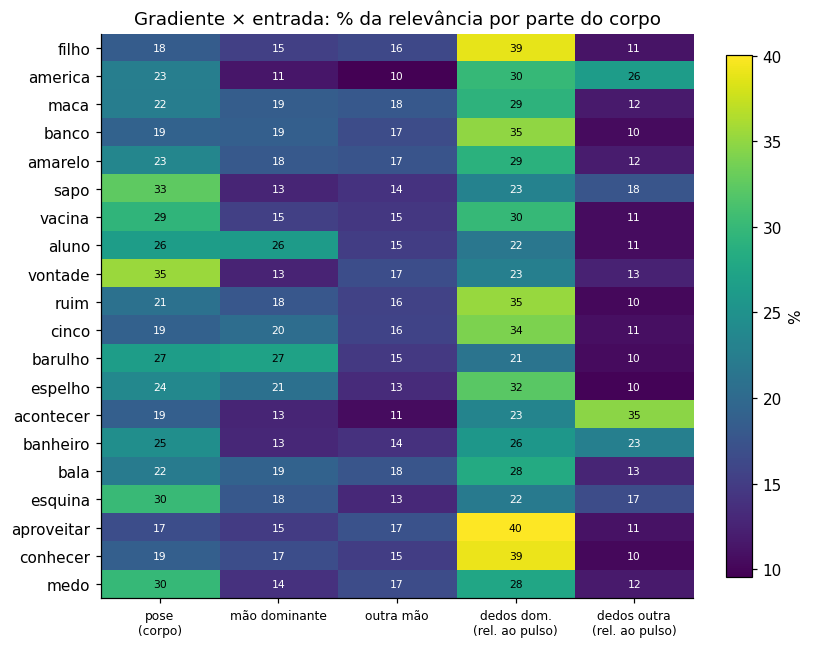

In [10]:
gxi_grupo = pd.DataFrame({g: gxi_tudo[:, grupo_col == g].sum(1).astype(float) for g in GRUPOS})
gxi_grupo = gxi_grupo.div(gxi_grupo.sum(axis=1), axis=0)                          # fração de cada grupo, por vídeo
n_canais = pd.Series({g: int((grupo_col == g).sum()) for g in GRUPOS})
resumo = pd.DataFrame({"canais": n_canais, "fração dos canais (%)": (100 * n_canais / F).round(1),
                       "fração da relevância (%)": (100 * gxi_grupo.mean()).round(1)})
resumo["relevância por canal (× média)"] = (resumo["fração da relevância (%)"] / resumo["fração dos canais (%)"]).round(2)
display(resumo)
resumo.to_csv(RES / "09_relevancia_grupos.csv")

por_classe = gxi_grupo.groupby(classes[y_tudo]).mean().loc[ordem]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(100 * por_classe, aspect="auto", cmap="viridis")
ax.set_yticks(range(K), por_classe.index); ax.set_xticks(range(len(GRUPOS)), [g.replace(" (", "\n(") for g in GRUPOS], fontsize=8)
for i in range(K):
    for jx in range(len(GRUPOS)):
        ax.text(jx, i, f"{100 * por_classe.iloc[i, jx]:.0f}", ha="center", va="center", fontsize=7,
                color="w" if por_classe.iloc[i, jx] < por_classe.values.max() * .6 else "k")
ax.set_title("Gradiente × entrada: % da relevância por parte do corpo")
plt.colorbar(im, ax=ax, fraction=.04, label="%")
plt.tight_layout(); salvar_fig("relevancia_partes"); plt.show()

## 5. Síntese

**Parte A — as CNNs do estado da arte não superam a CNN-1D simples.**

| Modelo | F1 macro (%) | Δ vs CNN-1D | p | Parâmetros | Treino (s) | Conjunto 3 sementes (%) |
|---|---|---|---|---|---|---|
| CNN-1D | 90,5 ± 2,7 | — | — | 197 mil | 45 | 91,6 |
| FCN | 90,8 ± 2,5 | +0,3 | 0,91 | 596 mil | 53 | 91,6 |
| ResNet | 84,7 ± 5,9 | −5,8 | 0,009 | 693 mil | 80 | 89,2 |
| InceptionTime | 87,3 ± 3,2 | −3,2 | 0,009 | 230 mil | 92 | 90,3 |

- A **FCN empata** com a CNN-1D (+0,3 p.p., p = 0,91, melhor em 7 de 12 pares) com 3 vezes mais parâmetros. Isso é esperado: ela é a mesma arquitetura com mais filtros e núcleos maiores.
- **ResNet e InceptionTime perdem de forma significativa** (p = 0,009 nas duas; a ResNet é melhor em só 1 dos 12 pares). São as redes mais profundas (9 convoluções e 6 módulos Inception, contra 3 convoluções) e atingem a melhor época mais cedo (24 e 31 épocas contra 40), sinal de que decoram os ~670 vídeos de treino mais rápido. A perda é maior nas rodadas 2 e 3, as de sinalizantes mais difíceis: a profundidade amplifica a diferença entre pessoas, em vez de ajudar.
- O **conjunto de sementes** ajuda todos os modelos e ajuda mais os instáveis: +1,1 p.p. na CNN-1D e +4,5 na ResNet, cujo desvio cai de 5,9 para 3,6. Mesmo assim, nenhum conjunto passa do conjunto da CNN-1D (91,6%), que custa 3 treinos e 3 inferências.
- Conclusão: com séries curtas (32 instantes), muitos canais (321) e poucos vídeos, o que limita o desempenho é a variação entre sinalizantes, não a capacidade da rede. O resultado repete o do notebook 07 (Transformers): **mais complexidade não compensa**.

**Parte B — o aumento de dados não melhora a CNN-1D + Δ.**

| Aumento | F1 macro (%) | Δ vs sem aumento | p | Treino − validação (p.p.) |
|---|---|---|---|---|
| sem aumento | 93,3 ± 2,4 | — | — | 5,9 |
| deformação do tempo | 92,9 ± 2,4 | −0,4 | 0,27 | 5,8 |
| escala | 93,0 ± 2,4 | −0,2 | 0,62 | 6,1 |
| deformação de amplitude | 91,8 ± 2,0 | −1,4 | 0,06 | 7,8 |
| combinação | 92,8 ± 2,3 | −0,5 | 0,38 | 7,6 |

- Nenhuma transformação traz ganho; a deformação de amplitude fica perto de uma perda significativa (−1,4 p.p., p = 0,06). A distância entre treino e validação **não diminui**: a rede continua chegando a ~100% no treino, só que com dados alterados.
- A explicação está no próprio pré-processamento. O que essas transformações simulam já foi removido antes: a **reamostragem para 32 instantes** normaliza a duração do sinal (a deformação do tempo só mexe na velocidade *dentro* do gesto), e a **normalização pelo corpo** (centro e largura dos ombros) já elimina a escala. O que realmente difere entre sinalizantes, como a configuração dos dedos e o estilo do movimento, não é coberto por deformações genéricas.
- O efeito depende da rodada: a combinação ganha 3,8 p.p. na rodada 0 e perde 2,9 na rodada 2. Isso reforça que o aumento genérico não ataca a causa do erro.
- O valor *sem aumento* (93,3%) é 0,7 p.p. maior do que o da CNN-1D + Δ no notebook 06 (92,6%), dentro do ruído de ~0,8 p.p. medido entre execuções. Aqui os lotes vêm de um gerador e a ordem dos vídeos muda.

**Parte C — onde a CNN-1D olha.**

- **Quando:** a evidência está no **núcleo do gesto**, aproximadamente entre os instantes 8 e 24. O início (preparação) e o fim (retração) quase não contam, e 54% da evidência está na 1ª metade. Isso explica o horizonte (notebook 05): com 50% do sinal a rede já viu o começo do núcleo e chega a 90,3%; o último quarto (a retração) quase não traz informação, e por isso a GRU, que decide pelo último estado, se saía melhor com 75% do sinal do que com 100%.
- Nos **erros**, o CAM é mais baixo e mais plano (pico ~0,5 contra ~0,87): a rede não encontra um trecho decisivo, em vez de olhar para o lugar errado.
- **Onde:** os **dedos da mão dominante** (forma da mão relativa ao pulso) são o grupo mais relevante: 29% da relevância com 19% dos canais, ou 1,6 vez a média por canal. O corpo fica na média (1,0), e a posição da mão dominante (0,9), a outra mão (0,8) e os dedos da outra mão (0,8) ficam abaixo. A configuração da mão, um dos parâmetros fonológicos de Libras, é o que mais distingue as palavras, o que também explica por que deformações genéricas da trajetória (Parte B) não ajudam.
- As exceções são informativas: em *acontecer*, *américa* e *banheiro*, os dedos da **outra** mão recebem 23–35% da relevância, o que indica sinais em que a mão não dominante tem papel ativo. Em *vontade*, *sapo* e *esquina*, o corpo (pose) é o grupo mais relevante, o que sugere sinais que se distinguem pelo lugar do corpo onde são feitos.

**Para o artigo:** o bônus II responde à pergunta "as técnicas do estado da arte em classificação de séries ajudam?" com um resultado negativo bem fundamentado. A arquitetura simples com a representação certa (Δ) ganha das arquiteturas profundas e do aumento de dados. Os mapas (CAM e gradiente × entrada) mostram por quê: a informação está no núcleo do gesto e na forma da mão dominante.

In [11]:
if IN_COLAB and not DRIVE_OK:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/resultados_09", "zip", str(BASE), "resultados")
    files.download("/content/resultados_09.zip")
else:
    print("resultados gravados em", RES)

resultados gravados em /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados
